# Five predictor configurations with a 96-arrival bank

**Complete** · seed 2026 · 80,000/80,000 arrivals replayed · ETA 0h 00m 00s

Paired scores through 80,000. Updated 2026-11-11T15:06:12+01:00.

## RMSE over the stream

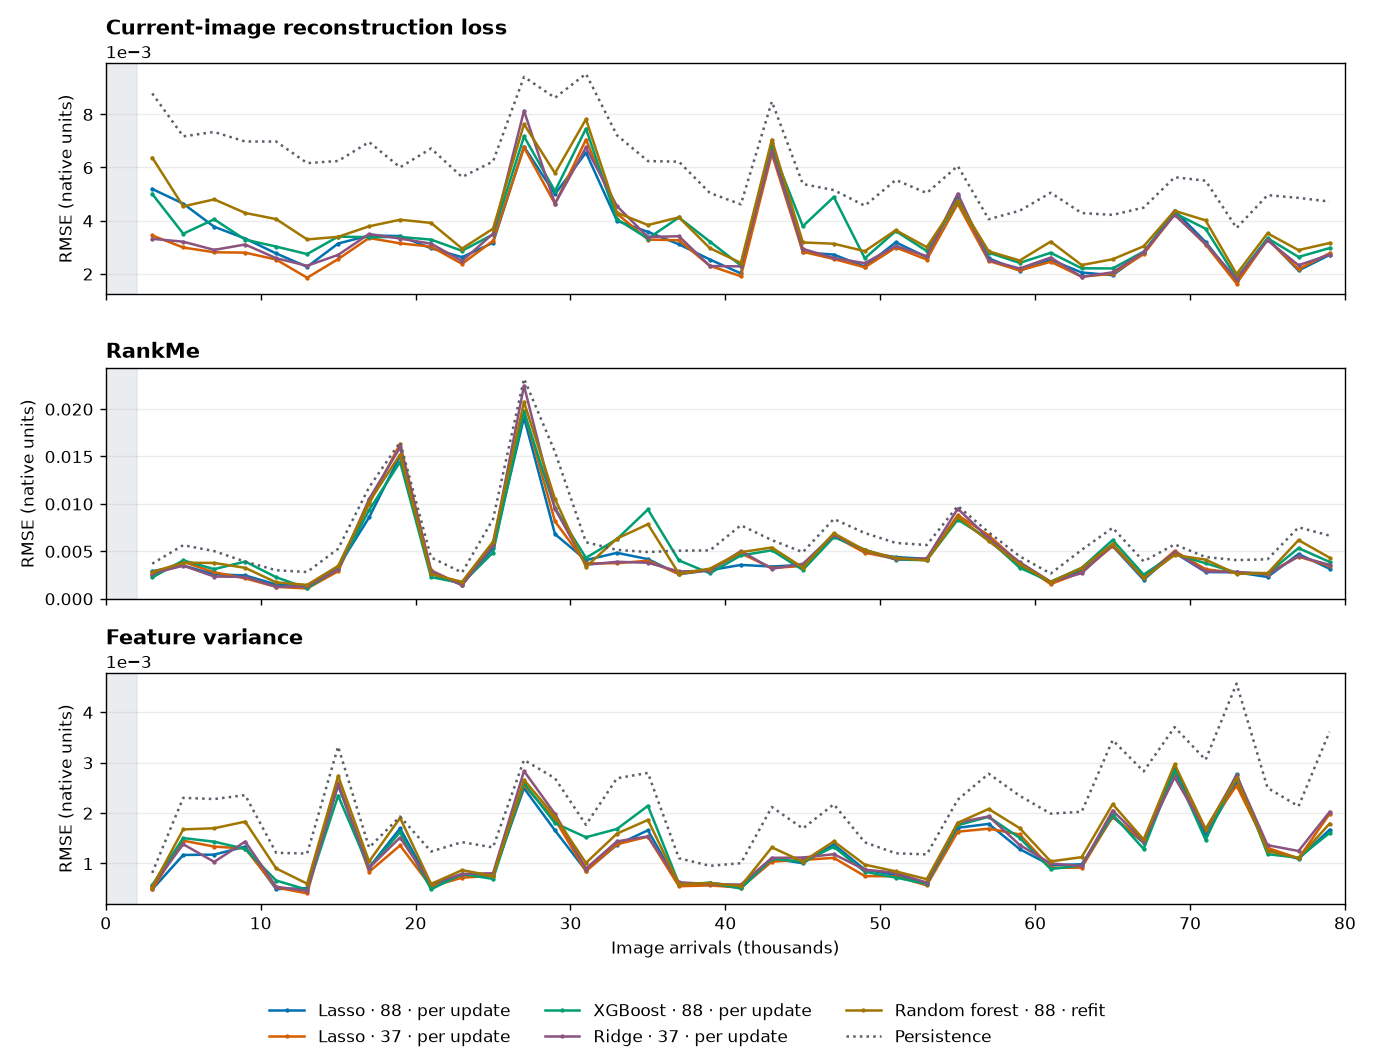

## Pooled forecast RMSE through the latest window

| Predictor | Current-image reconstruction loss | RankMe | Feature variance |
| --- | --- | --- | --- |
 | Lasso · 88 · per update | 0.00360398 | 0.00567437 | 0.00140083 | 
 | Lasso · 37 · per update | 0.00339051 | 0.00595122 | 0.00140271 | 
 | XGBoost · 88 · per update | 0.00383901 | 0.00612994 | 0.00145721 | 
 | Ridge · 37 · per update | 0.00355076 | 0.00625681 | 0.00146102 | 
 | Random forest · 88 · refit | 0.0041293 | 0.00634246 | 0.00155753 | 
 | Persistence | 0.00618011 | 0.00769676 | 0.00231984 | 

## Selection from notebooks 170 and 171

Rankings give equal weight to the two pooled RMSE reductions relative to persistence. Different feature sets count as distinct predictor configurations.

| Predictor | RankMe gain | Variance gain | Mean gain |
| --- | --- | --- | --- |
 | Lasso · 88 · per update | +19.1% | +39.8% | +29.5% | 
 | Lasso · 37 · per update | +14.0% | +38.6% | +26.3% | 
 | XGBoost · 88 · per update | +14.2% | +35.4% | +24.8% | 
 | Ridge · 37 · per update | +12.2% | +35.8% | +24.0% | 
 | Random forest · 88 · refit | +11.5% | +34.1% | +22.8% | 

## Protocol

The original recorded MAE actions are replayed from initialization. Current-image loss uses the original same-mask measurements. RankMe and variance use the same bank members before and after each update. The first 128 frames fill the bank. Each subsequent 96th arrival replaces the oldest frame after its outcome is recorded. The 88-input reference encoder and bank clusters are initialized at the end of bank fill.

Forecast scoring starts after the first 2,000 arrivals. Forecasts are scored on non-skip updates in 2,000-arrival windows. Per-update predictors learn only after each forecast is scored. All configurations retain their original model rules and block refits. Persistence forecasts zero change. Both feature sets are label-free.

In [ ]:
# Run this cell to watch the background worker.
from IPython.display import clear_output, display, Image, Markdown
from pathlib import Path
import json, time

folder = Path('C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\bank96-predictors')
while True:
    try:
        status = json.loads((folder / 'status.json').read_text(encoding='utf-8'))
        chart = (folder / 'rmse.png').read_bytes()
    except (FileNotFoundError, PermissionError, ValueError):
        time.sleep(2)
        continue
    eta = status['eta_seconds']
    estimate = f'{eta / 60:.1f} min' if eta is not None else 'estimating'
    clear_output(wait=True)
    display(Markdown(f"**{status['state']}** · {status['cursor']:,}/{status['limit']:,} arrivals · "
                     f"scored through {status['compared_through']:,} · ETA {estimate}"))
    display(Image(data=chart))
    if status['state'] in ('complete', 'failed', 'stopped'):
        if status['error']:
            display(Markdown(status['error']))
        break
    time.sleep(10)
